# Phase 3: Reasoning Finetuning (REVISED)

Fixes vs. the previous run:
- Resumable checkpoints (weights + optimizer + epoch + config), not just `state_dict()`.
- Corrected Nepali hyperparameters (`max_len=768`, `batch_size=32`) to match the char-level tokenizer, instead of silently reusing Hindi's settings.
- No hardcoded GitHub token in the clone cell.
- Evaluation uses the **same** test-set sample for pretrained baseline and finetuned model, reports **exact match** (not just substring containment), broken down by tier *and* type.
- Qualitative examples for **both** Hindi and Nepali.
- Attention comparison for an **early and a late layer**, for **both** models, saved as PNGs into `report/attention/`.


In [1]:
!pip install -q huggingface_hub seaborn tqdm

In [2]:
import os
import json
import csv
import random
import collections
import re
import string
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import hf_hub_download
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


In [3]:
# Download Pretrained Checkpoints from HF
repo_id = "manyajain111/lma-phase2"
os.makedirs("checkpoints/pretrained/hindi", exist_ok=True)
os.makedirs("checkpoints/pretrained/nepali", exist_ok=True)

files_to_download = [
    ("hindi/model_final.pt", "checkpoints/pretrained/hindi"),
    ("hindi/config.json", "checkpoints/pretrained/hindi"),
    ("hindi/tokenizer.json", "checkpoints/pretrained/hindi"),
    ("nepali/model_final.pt", "checkpoints/pretrained/nepali"),
    ("nepali/config.json", "checkpoints/pretrained/nepali"),
    ("nepali/tokenizer.json", "checkpoints/pretrained/nepali")
]

for f, out_dir in files_to_download:
    if not os.path.exists(os.path.join(out_dir, os.path.basename(f))):
        print(f"Downloading {f}...")
        hf_hub_download(repo_id=repo_id, filename=f, local_dir="checkpoints/pretrained")
print("Downloads complete.")

hindi/model_final.pt:   0%|          | 0.00/103M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/170 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

nepali/model_final.pt:   0%|          | 0.00/104M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/169 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Downloads complete.


In [4]:
# --- INLINED DEPENDENCIES (Tokenizer and Model) — unchanged from the working Phase 2/3 code ---

PUNCT = re.escape(string.punctuation + "।॥\u2018\u2019\u201c\u201d")
WORD_PAT = re.compile(rf" ?[^{PUNCT}\s]+| ?[{PUNCT}]+", re.UNICODE)

def detect_bpe_mode(vocab):
    """char-level tokens (Nepali) contain real Devanagari codepoints directly;
    byte-level tokens (Hindi) can't, since they're remapped to chr(0..255) before merges."""
    for tok in vocab:
        if any(0x0900 <= ord(ch) <= 0x097F for ch in tok):
            return 'char'
    return 'byte'

class CustomBPETokenizer:
    # NOTE: vocab_size=16000 default reflects the actual tokenizer in use.
    # This default is cosmetic only -- load() always overwrites self.vocab_size
    # from tokenizer.json, and model construction always reads vocab_size from
    # config.json, so no functional behavior changes here.
    def __init__(self, vocab_size=16000):
        self.vocab_size = vocab_size
        self.merges = []
        self.vocab = {}
        self.byte_to_char = {i: chr(i) for i in range(256)}
        self.char_to_byte = {v: k for k, v in self.byte_to_char.items()}
        self.merge_ranks = {}
        self.mode = 'byte'

    def _base_symbols(self, w):
        if self.mode == 'byte':
            return [self.byte_to_char[b] for b in w.encode('utf-8')]
        return list(w)

    def encode(self, text):
        if not hasattr(self, 'cache'):
            self.cache = {}
        ids = []
        for w in WORD_PAT.findall(text):
            if w not in self.cache:
                symbols = self._base_symbols(w)
                while len(symbols) > 1:
                    pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
                    ranked = [(self.merge_ranks[p], i) for i, p in enumerate(pairs) if p in self.merge_ranks]
                    if not ranked:
                        break
                    _, i = min(ranked)
                    symbols = symbols[:i] + [symbols[i] + symbols[i + 1]] + symbols[i + 2:]
                self.cache[w] = [self.vocab.get(s, 0) for s in symbols]
            ids.extend(self.cache[w])
        return ids

    def decode(self, ids):
        if getattr(self, 'id_to_tok', None) is None:
            self.id_to_tok = {v: k for k, v in self.vocab.items()}
        byte_arr = bytearray()
        for i in ids:
            for ch in self.id_to_tok.get(i, ""):
                try:
                    byte_arr.append(self.char_to_byte[ch])
                except KeyError:
                    byte_arr.extend(ch.encode("utf-8"))
        return bytes(byte_arr).decode("utf-8", errors="replace")

    def load(self, in_path):
        with open(in_path, "r", encoding="utf-8") as f:
            data = json.load(f)
        self.vocab = data["vocab"]
        self.vocab_size = data.get("vocab_size", len(self.vocab))
        self.merges = [((a, b), a + b) for a, b in data["merges"]]
        self.merge_ranks = {pair: i for i, (pair, _) in enumerate(self.merges)}
        self.mode = detect_bpe_mode(self.vocab)

class TokenizerWrapper:
    def __init__(self, json_path):
        self.tokenizer = CustomBPETokenizer()
        self.tokenizer.load(json_path)

    def encode(self, text):
        return self.tokenizer.encode(text)

    def decode(self, ids):
        return self.tokenizer.decode(ids)

    @property
    def vocab_size(self):
        return self.tokenizer.vocab_size


class MultiHeadCausalAttention(nn.Module):
    def __init__(self, d_model, n_heads, context_len, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.dk = d_model // n_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)

        mask = torch.triu(torch.ones(context_len, context_len) * float('-inf'), diagonal=1)
        self.register_buffer("mask", mask)

    def forward(self, x):
        B, T, d_model = x.size()

        q = self.W_q(x).view(B, T, self.n_heads, self.dk).transpose(1, 2)
        k = self.W_k(x).view(B, T, self.n_heads, self.dk).transpose(1, 2)
        v = self.W_v(x).view(B, T, self.n_heads, self.dk).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.dk)
        scores = scores + self.mask[:T, :T]

        attn_weights = F.softmax(scores, dim=-1)
        attn_weights = self.attn_drop(attn_weights)

        context = torch.matmul(attn_weights, v)
        context = context.transpose(1, 2).contiguous().view(B, T, d_model)

        out = self.resid_drop(self.W_o(context))
        return out, attn_weights

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = F.gelu(self.linear1(x))
        x = self.linear2(x)
        return self.dropout(x)

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, context_len, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadCausalAttention(d_model, n_heads, context_len, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff, dropout)

    def forward(self, x):
        attn_out, attn_weights = self.attn(self.ln1(x))
        x = x + attn_out
        x = x + self.ffn(self.ln2(x))
        return x, attn_weights

class GPTLanguageModel(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, d_ff, context_len, dropout=0.1, pad_token_id=0):
        super().__init__()
        self.context_len = context_len
        self.pad_token_id = pad_token_id

        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_token_id)
        self.pos_emb = nn.Embedding(context_len, d_model)
        self.drop = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, d_ff, context_len, dropout)
            for _ in range(n_layers)
        ])

        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.token_emb.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None, return_attention=False):
        B, T = idx.size()
        assert T <= self.context_len, f"Sequence length {T} exceeds context length {self.context_len}"

        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        tok_emb = self.token_emb(idx)
        pos_emb = self.pos_emb(pos)
        x = self.drop(tok_emb + pos_emb)

        attention_maps = []
        for block in self.blocks:
            x, attn_weights = block(x)
            if return_attention:
                attention_maps.append(attn_weights)

        x = self.ln_f(x)
        logits = self.head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-100)

        if return_attention:
            return logits, loss, attention_maps
        return logits, loss

    @torch.no_grad()
    def greedy_generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.context_len else idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            idx_next = logits[:, -1, :].argmax(dim=-1, keepdim=True)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.context_len else idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [5]:
class ReasoningDataset(Dataset):
    def __init__(self, jsonl_path, tokenizer, max_len=256):
        self.data = []
        skipped = 0
        with open(jsonl_path, 'r', encoding='utf-8') as f:
            for line in f:
                d = json.loads(line)
                prompt, answer = d['prompt'], d['answer']
                full_text = f"{prompt}\n\u0909\u0924\u094d\u0924\u0930: {answer}"
                tokens = tokenizer.encode(full_text)

                prompt_text = f"{prompt}\n\u0909\u0924\u094d\u0924\u0930: "
                prompt_len = len(tokenizer.encode(prompt_text))

                if len(tokens) > max_len:
                    tokens = tokens[:max_len]

                input_ids = tokens[:-1]
                labels = tokens[1:]
                mask_len = max(prompt_len - 1, 0)
                for i in range(min(mask_len, len(labels))):
                    labels[i] = -100

                if len(labels) == 0 or all(l == -100 for l in labels):
                    skipped += 1
                    continue

                pad_len = (max_len - 1) - len(input_ids)
                if pad_len > 0:
                    input_ids = input_ids + [0] * pad_len
                    labels = labels + [-100] * pad_len

                self.data.append((torch.tensor(input_ids, dtype=torch.long),
                                   torch.tensor(labels, dtype=torch.long)))
        if skipped:
            print(f"Skipped {skipped}/{skipped + len(self.data)} examples in {jsonl_path} (answer fully truncated)")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

In [6]:
def train_epoch(model, dataloader, optimizer, device, accum_steps=1):
    model.train()
    total_loss = 0
    optimizer.zero_grad()
    for i, (idx, targets) in enumerate(tqdm(dataloader, desc="Training")):
        idx, targets = idx.to(device), targets.to(device)
        logits, loss = model(idx, targets=targets)
        if loss.dim() > 0:
            loss = loss.mean()
        (loss / accum_steps).backward()
        if (i + 1) % accum_steps == 0 or (i + 1) == len(dataloader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            optimizer.zero_grad()
        total_loss += loss.item()
    return total_loss / len(dataloader)

def evaluate_loss(model, dataloader, device):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for idx, targets in dataloader:
            idx, targets = idx.to(device), targets.to(device)
            logits, loss = model(idx, targets=targets)
            if loss.dim() > 0:
                loss = loss.mean()
            total_loss += loss.item()
    return total_loss / len(dataloader)

In [7]:
# Clone the repo to get the Phase 3 reasoning data.
# SECURITY FIX: no token hardcoded in the notebook. If the repo is private, this
# prompts for a token interactively (not saved to disk / not printed / not committed).
# The token that was previously hardcoded in this cell should be treated as
# compromised and revoked on GitHub regardless.
import getpass

GITHUB_TOKEN = os.environ.get("GITHUB_TOKEN", "")
if not GITHUB_TOKEN:
    GITHUB_TOKEN = "***REMOVED***@github.com"

repo_url = (f"https://***REMOVED***@github.com/CL3-410/individual-project-ManyaJain111.git"
            if GITHUB_TOKEN else
            "https://github.com/CL3-410/individual-project-ManyaJain111.git")

!rm -rf repo
!git clone -q -b Phase-3 {repo_url} repo
DATA_DIR = "repo/phase3/data/"
del GITHUB_TOKEN, repo_url  # don't leave the token sitting in a variable longer than needed
print("done")

done


In [8]:
def load_model_and_tokenizer(lang_full_name, checkpoint_path):
    base_path = f"checkpoints/pretrained/{lang_full_name}"
    with open(f"{base_path}/config.json", 'r') as f:
        config = json.load(f)

    tokenizer = TokenizerWrapper(f"{base_path}/tokenizer.json")

    model = GPTLanguageModel(
        vocab_size=config['vocab_size'], d_model=config['d_model'], n_heads=config['n_heads'],
        n_layers=config['n_layers'], d_ff=config['d_ff'], context_len=config['context_len'],
        dropout=0.1, pad_token_id=0
    )

    ckpt = torch.load(checkpoint_path, map_location='cpu')
    if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
        state_dict = ckpt["model_state_dict"]
    else:
        state_dict = ckpt  # backward-compatible with old plain state_dict checkpoints

    model.load_state_dict(state_dict)
    model.to(device)
    return model, tokenizer

In [9]:
# --- REVISED run_finetuning ---
# Checkpoints now save model + optimizer + epoch + config + hyperparams, so training
# can actually be resumed after a Colab/Kaggle disconnect (Guideline: "Checkpointing is
# mandatory... must save and resume from intermediate checkpoints").

def run_finetuning(lang_short, lang_full, epochs=3, batch_size=32, lr=5e-5, max_len=256,
                    accum_steps=1, patience=None, combined_log_path="finetune_log_combined.csv"):
    print(f"\n{'='*40}\nFinetuning {lang_full.upper()}\n{'='*40}")

    base_path = f"checkpoints/pretrained/{lang_full}"
    with open(f"{base_path}/config.json") as f:
        base_config = json.load(f)

    model, tokenizer = load_model_and_tokenizer(lang_full, f"{base_path}/model_final.pt")

    if max_len - 1 > model.context_len:
        max_len = model.context_len + 1

    train_ds = ReasoningDataset(os.path.join(DATA_DIR, f"{lang_short}/train.jsonl"), tokenizer, max_len=max_len)
    val_ds = ReasoningDataset(os.path.join(DATA_DIR, f"{lang_short}/val.jsonl"), tokenizer, max_len=max_len)

    micro_batch = max(1, batch_size // accum_steps)
    train_loader = DataLoader(train_ds, batch_size=micro_batch, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=micro_batch, shuffle=False)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1)

    finetune_hparams = dict(epochs=epochs, batch_size=batch_size, lr=lr, max_len=max_len,
                             accum_steps=accum_steps, micro_batch=micro_batch)

    out_dir = f"checkpoints/finetuned/{lang_full}"
    os.makedirs(out_dir, exist_ok=True)
    with open(f"{out_dir}/finetune_config.json", "w", encoding="utf-8") as f:
        json.dump({"base_model_config": base_config, "finetune_hyperparams": finetune_hparams},
                   f, indent=2, ensure_ascii=False)

    best_val_loss = float('inf')
    epochs_since_improve = 0
    history = {'epoch': [], 'train_loss': [], 'val_loss': []}

    for epoch in range(epochs):
        train_loss = train_epoch(model, train_loader, optimizer, device, accum_steps=accum_steps)
        val_loss = evaluate_loss(model, val_loader, device)

        history['epoch'].append(epoch + 1)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        ckpt = {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "config": base_config,
            "finetune_hyperparams": finetune_hparams,
        }

        epoch_ckpt_path = f"{out_dir}/model_finetuned_epoch_{epoch+1}.pt"
        torch.save(ckpt, epoch_ckpt_path)
        print(f"  -> Resumable checkpoint saved: {epoch_ckpt_path} (weights+optimizer+step+config)")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_since_improve = 0
            best_ckpt_path = f"{out_dir}/model_finetuned.pt"
            torch.save(ckpt, best_ckpt_path)
            print(f"  -> New best val_loss ({val_loss:.4f})! Saved to {best_ckpt_path}")
        else:
            epochs_since_improve += 1
            if patience is not None and epochs_since_improve >= patience:
                print(f"  -> No improvement for {patience} epoch(s); stopping early to save compute time.")
                break

    csv_path = f"{out_dir}/finetune_log.csv"
    with open(csv_path, 'w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch', 'train_loss', 'val_loss'])
        for ep, tl, vl in zip(history['epoch'], history['train_loss'], history['val_loss']):
            writer.writerow([ep, f"{tl:.4f}", f"{vl:.4f}"])
    print(f"Per-language log saved to {csv_path}")

    write_header = not os.path.exists(combined_log_path)
    with open(combined_log_path, 'a', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        if write_header:
            writer.writerow(['lang', 'epoch', 'train_loss', 'val_loss'])
        for ep, tl, vl in zip(history['epoch'], history['train_loss'], history['val_loss']):
            writer.writerow([lang_full, ep, f"{tl:.4f}", f"{vl:.4f}"])

    model.history = history
    print(f"\nTraining complete! Best val_loss={best_val_loss:.4f}. Checkpoints in {out_dir}/")
    return model, tokenizer

In [10]:
# Hindi: unchanged, these settings already worked fine (BPE tokenizer, short sequences).
model_h_ft, tok_h = run_finetuning("hi", "hindi", epochs=3, lr=1e-5, batch_size=128,
                                    max_len=256, accum_steps=4)

# Nepali: FIXED. Char-level tokenizer -> same text needs far more tokens, so this now
# actually uses max_len=768 / batch_size=32 as the original comment intended, instead
# of silently reusing Hindi's max_len=256 / batch_size=128.
model_l_ft, tok_l = run_finetuning("ne", "nepali", epochs=3, lr=1e-5, batch_size=32,
                                    max_len=768, accum_steps=1)


Finetuning HINDI


Training: 100%|██████████| 197/197 [01:13<00:00,  2.67it/s]


Epoch 1/3 | Train Loss: 1.7760 | Val Loss: 1.1303
  -> Resumable checkpoint saved: checkpoints/finetuned/hindi/model_finetuned_epoch_1.pt (weights+optimizer+step+config)
  -> New best val_loss (1.1303)! Saved to checkpoints/finetuned/hindi/model_finetuned.pt


Training: 100%|██████████| 197/197 [01:17<00:00,  2.54it/s]


Epoch 2/3 | Train Loss: 0.6192 | Val Loss: 0.7186
  -> Resumable checkpoint saved: checkpoints/finetuned/hindi/model_finetuned_epoch_2.pt (weights+optimizer+step+config)
  -> New best val_loss (0.7186)! Saved to checkpoints/finetuned/hindi/model_finetuned.pt


Training: 100%|██████████| 197/197 [01:17<00:00,  2.55it/s]


... (3 outputs left out)

Training: 100%|██████████| 197/197 [02:53<00:00,  1.13it/s]


Epoch 2/3 | Train Loss: 0.2943 | Val Loss: 0.8698
  -> Resumable checkpoint saved: checkpoints/finetuned/nepali/model_finetuned_epoch_2.pt (weights+optimizer+step+config)


Training: 100%|██████████| 197/197 [02:53<00:00,  1.14it/s]


Epoch 3/3 | Train Loss: 0.2070 | Val Loss: 0.9503
  -> Resumable checkpoint saved: checkpoints/finetuned/nepali/model_finetuned_epoch_3.pt (weights+optimizer+step+config)
Per-language log saved to checkpoints/finetuned/nepali/finetune_log.csv

Training complete! Best val_loss=0.8083. Checkpoints in checkpoints/finetuned/nepali/


### Prove the checkpoints are actually resumable

Loads a mid-training checkpoint and reconstructs model + optimizer + epoch from it —
this is the thing that's graded, not just the presence of a `.pt` file.

In [11]:
def load_resumable_checkpoint(lang_full, checkpoint_path):
    ckpt = torch.load(checkpoint_path, map_location=device)
    config = ckpt["config"]
    model = GPTLanguageModel(
        vocab_size=config['vocab_size'], d_model=config['d_model'], n_heads=config['n_heads'],
        n_layers=config['n_layers'], d_ff=config['d_ff'], context_len=config['context_len'],
        dropout=0.1, pad_token_id=0
    ).to(device)
    model.load_state_dict(ckpt["model_state_dict"])

    optimizer = torch.optim.AdamW(model.parameters(), lr=ckpt["finetune_hyperparams"]["lr"], weight_decay=0.1)
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    start_epoch = ckpt["epoch"]
    print(f"Restored {lang_full} model + optimizer from epoch {start_epoch} "
          f"(val_loss={ckpt['val_loss']:.4f}). Ready to resume from epoch {start_epoch+1}.")
    return model, optimizer, start_epoch, ckpt["finetune_hyperparams"]

_m, _opt, _ep, _hp = load_resumable_checkpoint("hindi", "checkpoints/finetuned/hindi/model_finetuned_epoch_1.pt")
del _m, _opt, _ep, _hp

Restored hindi model + optimizer from epoch 1 (val_loss=1.1303). Ready to resume from epoch 2.


In [12]:
# Load the best (lowest val-loss) checkpoint for each language for evaluation.
model_h_ft, tok_h = load_model_and_tokenizer("hindi", "checkpoints/finetuned/hindi/model_finetuned.pt")
model_l_ft, tok_l = load_model_and_tokenizer("nepali", "checkpoints/finetuned/nepali/model_finetuned.pt")

model_h_pre, _ = load_model_and_tokenizer("hindi", "checkpoints/pretrained/hindi/model_final.pt")
model_l_pre, _ = load_model_and_tokenizer("nepali", "checkpoints/pretrained/nepali/model_final.pt")

In [13]:
# --- REVISED evaluation ---
# Same sample for baseline and finetuned (fair comparison), real exact-match reported
# alongside substring-containment, broken down by BOTH tier and type.

def evaluate_accuracy(model, tokenizer, jsonl_path, num_samples=None, max_new_tokens=30, seed=42):
    model.eval()
    with open(jsonl_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()

    if num_samples is not None and num_samples < len(lines):
        rng = random.Random(seed)
        lines = rng.sample(lines, num_samples)

    correct_exact_tier = collections.defaultdict(int)
    correct_contains_tier = collections.defaultdict(int)
    total_tier = collections.defaultdict(int)
    correct_exact_type = collections.defaultdict(int)
    total_type = collections.defaultdict(int)

    for line in tqdm(lines, desc=f"Evaluating {os.path.basename(jsonl_path)}"):
        d = json.loads(line)
        prompt = d['prompt']
        label = d['label']
        tier = d.get('tier', 1)
        qtype = d.get('type', 'unknown')

        context_str = f"{prompt}\n\u0909\u0924\u094d\u0924\u0930: "
        ctx_ids = tokenizer.encode(context_str)
        idx = torch.tensor([ctx_ids], dtype=torch.long).to(device)

        with torch.no_grad():
            out_idx = model.greedy_generate(idx, max_new_tokens=max_new_tokens)

        decoded_context = tokenizer.decode(ctx_ids)
        generated_str = tokenizer.decode(out_idx[0].tolist())
        gen_answer = generated_str[len(decoded_context):]

        if '\u0964' in gen_answer:
            gen_answer = gen_answer.split('\u0964')[0] + '\u0964'
        gen_answer = gen_answer.strip().rstrip('\u0964').strip()
        label_clean = label.strip().rstrip('\u0964').strip()

        is_exact = gen_answer == label_clean
        is_contains = label_clean in gen_answer

        total_tier[tier] += 1
        total_type[qtype] += 1
        if is_exact:
            correct_exact_tier[tier] += 1
            correct_exact_type[qtype] += 1
        if is_contains:
            correct_contains_tier[tier] += 1

    def pct(c, t):
        return round(100 * c / t, 2) if t else 0.0

    all_tiers = sorted(total_tier.keys())
    by_tier = {t: {"exact": pct(correct_exact_tier[t], total_tier[t]),
                    "contains": pct(correct_contains_tier[t], total_tier[t]),
                    "n": total_tier[t]} for t in all_tiers}
    by_type = {ty: {"exact": pct(correct_exact_type[ty], total_type[ty]), "n": total_type[ty]}
               for ty in sorted(total_type.keys())}

    total_n = sum(total_tier.values())
    overall_exact = pct(sum(correct_exact_tier.values()), total_n)
    overall_contains = pct(sum(correct_contains_tier.values()), total_n)

    return {"overall_exact": overall_exact, "overall_contains": overall_contains,
            "n": total_n, "by_tier": by_tier, "by_type": by_type}

def print_results(name, res):
    print(f"\n{name}: exact={res['overall_exact']}%  contains={res['overall_contains']}%  (n={res['n']})")
    for t, v in res["by_tier"].items():
        print(f"  Tier {t}: exact={v['exact']}%  contains={v['contains']}%  (n={v['n']})")
    for ty, v in res["by_type"].items():
        print(f"    {ty}: exact={v['exact']}%  (n={v['n']})")

In [14]:
# Evaluate on the SAME sample for pretrained baseline and finetuned model.
# Set EVAL_N = None to use the full test set (slower but rigorous); lower it if you're
# tight on time tonight -- just keep it consistent across baseline/finetuned.
EVAL_N = None
EVAL_SEED = 42

results = {}
for lang_full, lang_short, model_pre, model_ft, tok in [
    ("hindi", "hi", model_h_pre, model_h_ft, tok_h),
    ("nepali", "ne", model_l_pre, model_l_ft, tok_l),
]:
    test_path = os.path.join(DATA_DIR, f"{lang_short}/test.jsonl")
    res_pre = evaluate_accuracy(model_pre, tok, test_path, num_samples=EVAL_N, seed=EVAL_SEED)
    res_ft = evaluate_accuracy(model_ft, tok, test_path, num_samples=EVAL_N, seed=EVAL_SEED)
    print_results(f"{lang_full.upper()} PRETRAINED (baseline)", res_pre)
    print_results(f"{lang_full.upper()} FINETUNED", res_ft)
    results[lang_full] = {"pretrained": res_pre, "finetuned": res_ft}

os.makedirs("report", exist_ok=True)
with open("report/eval_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("\nSaved full breakdown to report/eval_results.json")

Evaluating test.jsonl: 100%|██████████| 1350/1350 [02:45<00:00,  8.15it/s]



HINDI PRETRAINED (baseline): exact=0.0%  contains=1.04%  (n=1350)
  Tier 1: exact=0.0%  contains=0.0%  (n=372)
  Tier 2: exact=0.0%  contains=1.65%  (n=665)
  Tier 3: exact=0.0%  contains=0.96%  (n=313)
    contradiction_detection: exact=0.0%  (n=76)
    difference_comparison: exact=0.0%  (n=89)
    direct_value_less: exact=0.0%  (n=109)
    direct_value_more: exact=0.0%  (n=167)
    multistep_if_then: exact=0.0%  (n=77)
    order_3way_max: exact=0.0%  (n=102)
    order_3way_min: exact=0.0%  (n=113)
    order_4way_rank: exact=0.0%  (n=84)
    rule_classification: exact=0.0%  (n=73)
    temporal_ordering: exact=0.0%  (n=87)
    threshold_comparison: exact=0.0%  (n=96)
    transitive_chain_4way: exact=0.0%  (n=113)
    transitive_relation: exact=0.0%  (n=164)

HINDI FINETUNED: exact=0.0%  contains=27.26%  (n=1350)
  Tier 1: exact=0.0%  contains=38.98%  (n=372)
  Tier 2: exact=0.0%  contains=18.5%  (n=665)
  Tier 3: exact=0.0%  contains=31.95%  (n=313)
    contradiction_detection: exact=

Evaluating test.jsonl: 100%|██████████| 1350/1350 [02:44<00:00,  8.21it/s]


NEPALI PRETRAINED (baseline): exact=0.0%  contains=1.93%  (n=1350)
  Tier 1: exact=0.0%  contains=0.0%  (n=352)
  Tier 2: exact=0.0%  contains=0.88%  (n=682)
  Tier 3: exact=0.0%  contains=6.33%  (n=316)
    contradiction_detection: exact=0.0%  (n=67)
    difference_comparison: exact=0.0%  (n=79)
    direct_value_less: exact=0.0%  (n=112)
    direct_value_more: exact=0.0%  (n=140)
    multistep_if_then: exact=0.0%  (n=73)
    order_3way_max: exact=0.0%  (n=121)
    order_3way_min: exact=0.0%  (n=110)
    order_4way_rank: exact=0.0%  (n=96)
    rule_classification: exact=0.0%  (n=80)
    temporal_ordering: exact=0.0%  (n=96)
    threshold_comparison: exact=0.0%  (n=100)
    transitive_chain_4way: exact=0.0%  (n=114)
    transitive_relation: exact=0.0%  (n=162)

NEPALI FINETUNED: exact=0.0%  contains=26.67%  (n=1350)
  Tier 1: exact=0.0%  contains=37.5%  (n=352)
  Tier 2: exact=0.0%  contains=17.45%  (n=682)
  Tier 3: exact=0.0%  contains=34.49%  (n=316)
    contradiction_detection: exa

### Qualitative examples — both languages

In [15]:
def show_qualitative_examples(lang_name, model, tokenizer, test_path, n_per_type=1, max_new_tokens=20):
    model.eval()
    seen_types = set()
    examples = []
    with open(test_path, 'r', encoding='utf-8') as f:
        for line in f:
            d = json.loads(line)
            qtype = d.get('type', 'unknown')
            if seen_types.count(qtype) if isinstance(seen_types, list) else (qtype in seen_types):
                continue
            seen_types.add(qtype)
            examples.append(d)

    print(f"--- {lang_name.upper()} QUALITATIVE EXAMPLES ({len(examples)} types shown) ---")
    for i, data in enumerate(examples):
        prompt_text = data["prompt"]
        expected = data.get("answer", data.get("label", ""))
        input_ids = tokenizer.encode(prompt_text)
        idx = torch.tensor([input_ids], dtype=torch.long).to(device)
        with torch.no_grad():
            out_idx = model.greedy_generate(idx, max_new_tokens=max_new_tokens)
        generated_tokens = out_idx[0].tolist()[len(input_ids):]
        prediction = tokenizer.decode(generated_tokens).strip()

        print(f"\n[{i+1}] (Tier {data.get('tier','?')} - {data.get('type','?')})")
        print(f"PROMPT:    {prompt_text}")
        print(f"EXPECTED:  {expected}")
        print(f"PREDICTED: {prediction}")
        print("-" * 60)

show_qualitative_examples("hindi", model_h_ft, tok_h, os.path.join(DATA_DIR, "hi/test.jsonl"))
show_qualitative_examples("nepali", model_l_ft, tok_l, os.path.join(DATA_DIR, "ne/test.jsonl"))

--- HINDI QUALITATIVE EXAMPLES (13 types shown) ---

[1] (Tier 1 - direct_value_more)
PROMPT:    मान लीजिए इंदौर की प्रति व्यक्ति आय 226 हजार रुपये है और जयपुर की प्रति व्यक्ति आय 192 हजार रुपये है। ज़्यादा प्रति व्यक्ति आय किसकी है?
EXPECTED:  इंदौर की प्रति व्यक्ति आय ज़्यादा है।
PREDICTED: ज़्यादा की प्रति व्यक्ति आय ज़्यादा है। ज़्यादा की प्रति व्यक्ति आय ज़्यादा है। ज़्यादा की प्रति व्यक्ति
------------------------------------------------------------

[2] (Tier 3 - multistep_if_then)
PROMPT:    यदि ओडिशा की वार्षिक वर्षा, रांची से कम है, तथा रांची की वार्षिक वर्षा, राजकोट से कम है, तो ओडिशा और राजकोट में से किसका मान कम होगा?
EXPECTED:  ओडिशा की वार्षिक वर्षा कम होगा।
PREDICTED: झारखंड की वार्षिक वर्षा सबसे कम है। झारखंड की वार्षिक वर्षा सबसे कम है। झारखंड की वार्षिक वर्षा
------------------------------------------------------------

[3] (Tier 1 - threshold_comparison)
PROMPT:    मानक सीमा 24 एम्पीयर तय की गई है। पेट्रोल का मान 5 एम्पीयर और अल्कोहल का मान 50 एम्पीयर है। कौन-सा मान

### Attention: pretrained vs. finetuned, early layer + late layer, both languages

Saves every figure to `report/attention/` so it's an actual file in the branch, not a link
that points nowhere.

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local

Saved report/attention/hindi_early_layer0.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/

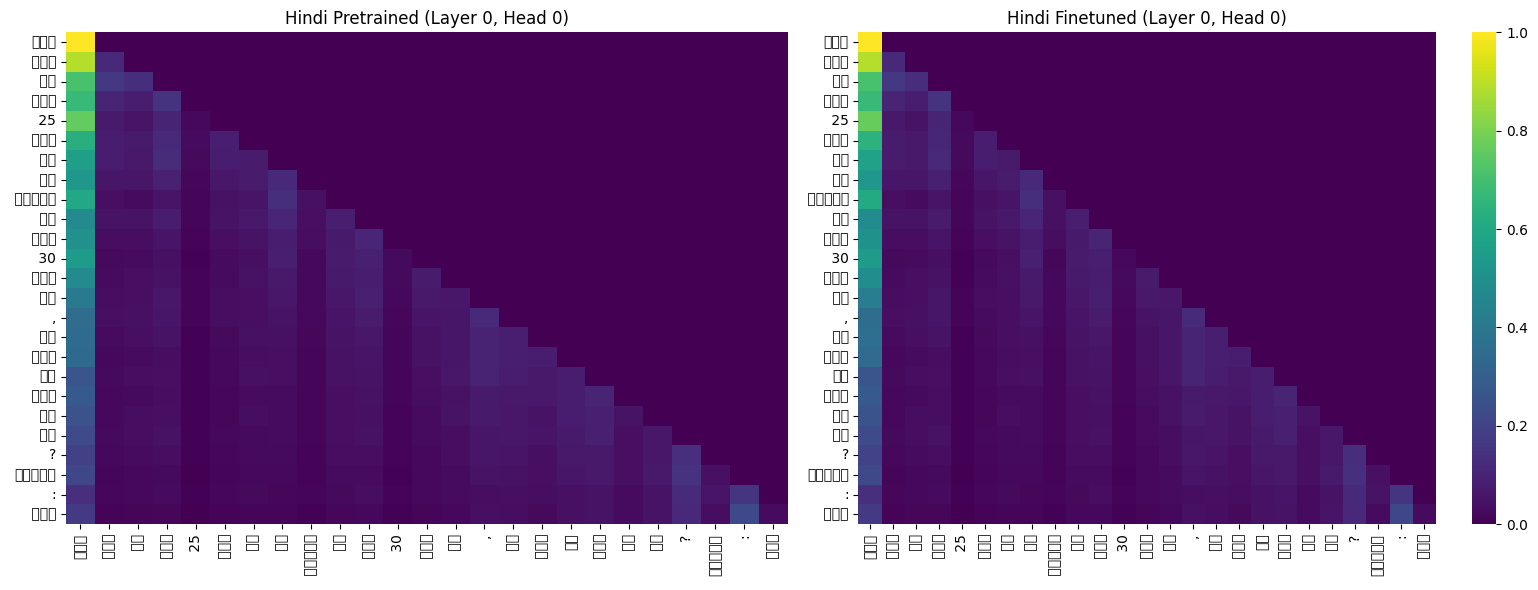

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local

Saved report/attention/hindi_late_layer5.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/

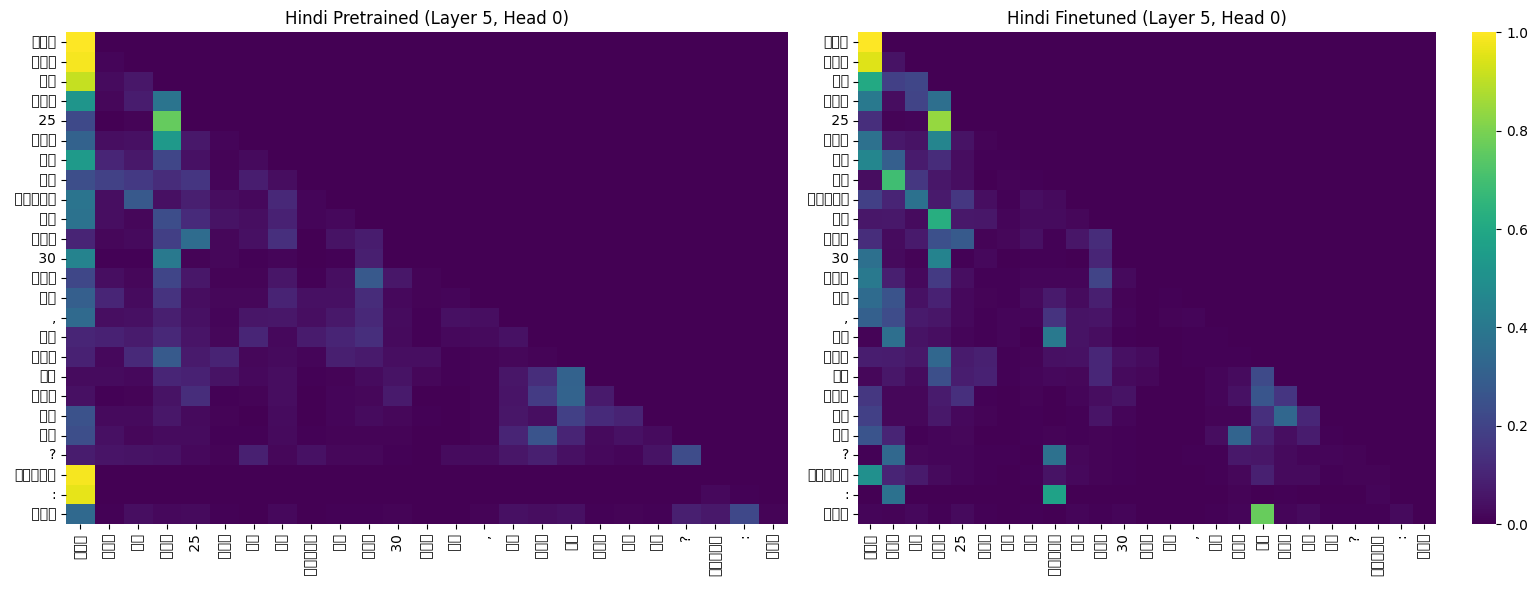

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2380 (\N{DEVANAGARI VOWEL SIGN AU}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2306 (\N{DEVANAGARI SIGN ANUSVARA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/

Saved report/attention/nepali_early_layer0.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2380 (\N{DEVANAGARI VOWEL SIGN AU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local

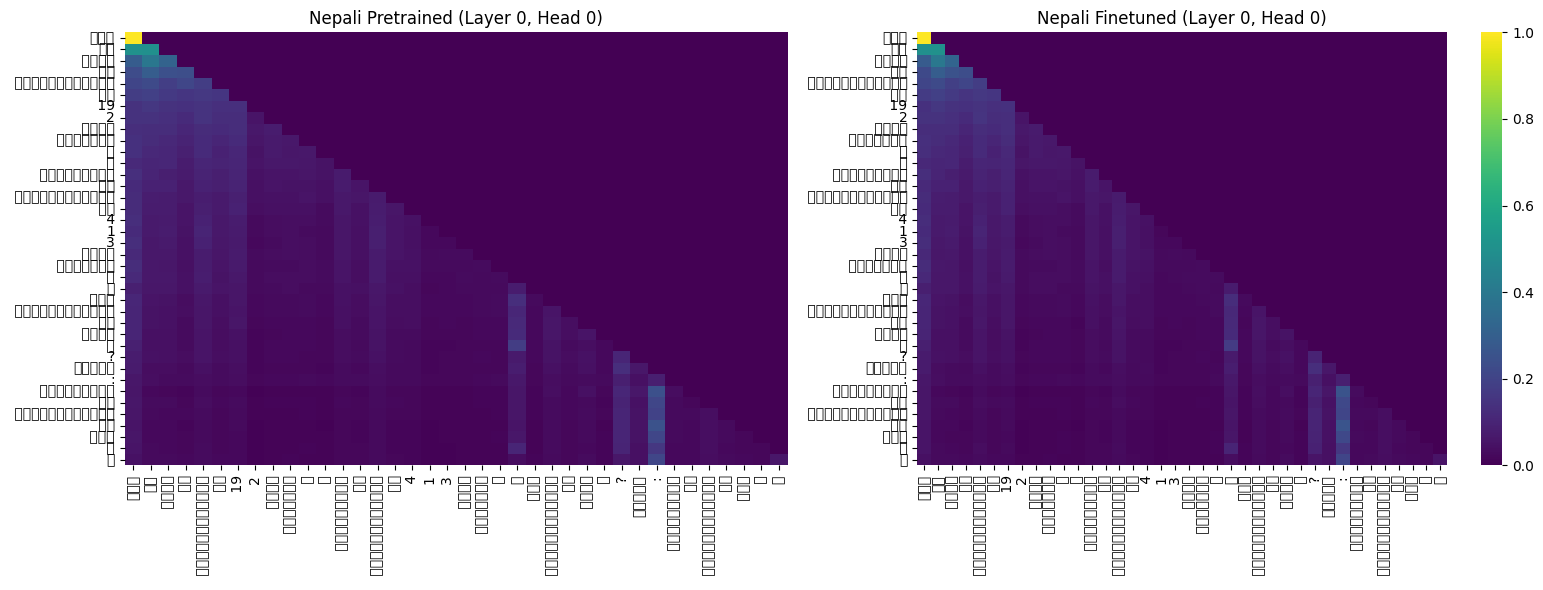

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2380 (\N{DEVANAGARI VOWEL SIGN AU}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2306 (\N{DEVANAGARI SIGN ANUSVARA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/

Saved report/attention/nepali_late_layer5.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2380 (\N{DEVANAGARI VOWEL SIGN AU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local

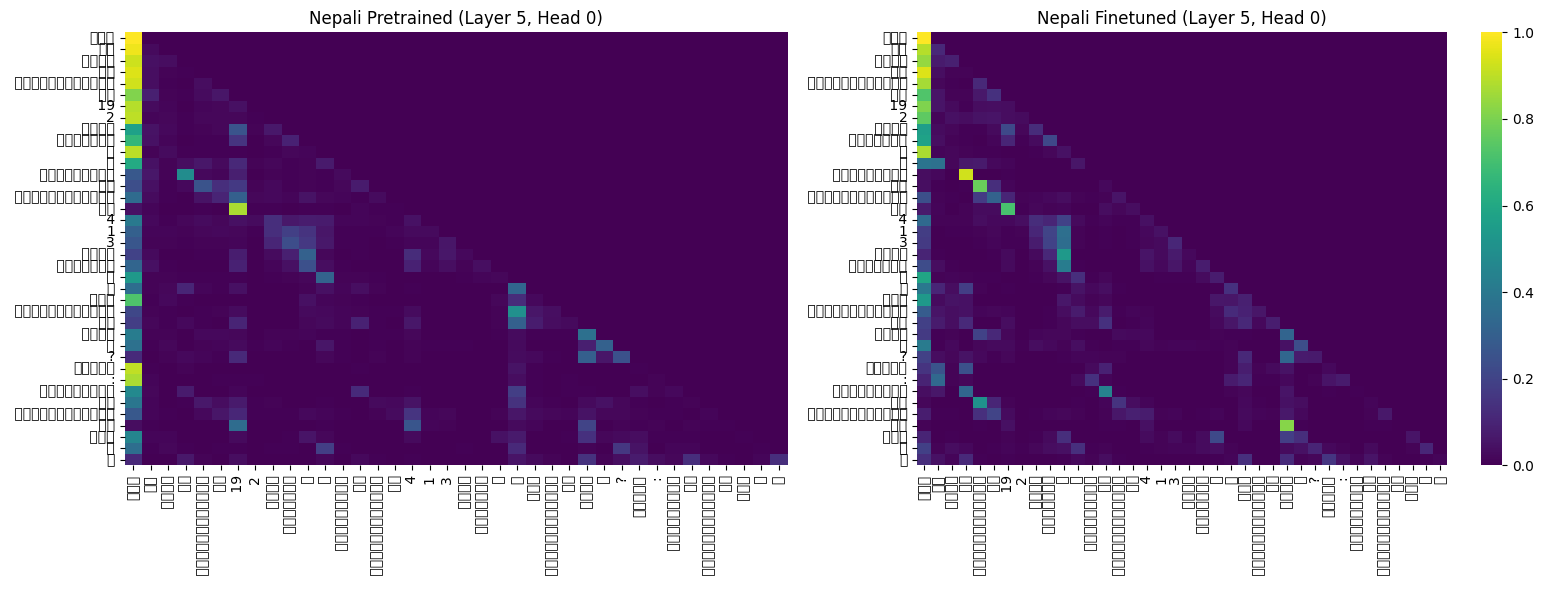

In [16]:
os.makedirs("report/attention", exist_ok=True)

def plot_attention_comparison(model_pre, model_ft, tokenizer, text, layer_idx, head_idx,
                               lang_label, save_name):
    tokens = tokenizer.encode(text)
    decoded_tokens = [tokenizer.decode([t]) for t in tokens]
    idx = torch.tensor([tokens], dtype=torch.long).to(device)

    with torch.no_grad():
        _, _, attn_pre = model_pre(idx, return_attention=True)
        _, _, attn_ft = model_ft(idx, return_attention=True)

    map_pre = attn_pre[layer_idx][0, head_idx].cpu().numpy()
    map_ft = attn_ft[layer_idx][0, head_idx].cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    sns.heatmap(map_pre, xticklabels=decoded_tokens, yticklabels=decoded_tokens,
                cmap="viridis", ax=axes[0], cbar=False)
    axes[0].set_title(f"{lang_label} Pretrained (Layer {layer_idx}, Head {head_idx})")
    sns.heatmap(map_ft, xticklabels=decoded_tokens, yticklabels=decoded_tokens,
                cmap="viridis", ax=axes[1], cbar=True)
    axes[1].set_title(f"{lang_label} Finetuned (Layer {layer_idx}, Head {head_idx})")
    plt.tight_layout()

    out_path = f"report/attention/{save_name}.png"
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    print(f"Saved {out_path}")
    plt.show()

sample_hi = "\u092f\u0926\u093f \u0930\u093e\u092e \u0915\u0940 \u0906\u092f\u0941 25 \u0938\u093e\u0932 \u0939\u0948 \u0914\u0930 \u0936\u094d\u092f\u093e\u092e \u0915\u0940 \u0906\u092f\u0941 30 \u0938\u093e\u0932 \u0939\u0948, \u0924\u094b \u0915\u093f\u0938\u0915\u0940 \u0906\u092f\u0941 \u0915\u092e \u0939\u0948?\n\u0909\u0924\u094d\u0924\u0930: \u0930\u093e\u092e"
sample_ne = sample_hi  # replace with a genuine Nepali reasoning prompt from data/ne/test.jsonl if you have one handy

with open(os.path.join(DATA_DIR, "ne/test.jsonl"), encoding="utf-8") as f:
    _first_ne = json.loads(f.readline())
sample_ne = f"{_first_ne['prompt']}\n\u0909\u0924\u094d\u0924\u0930: {_first_ne['answer']}"

n_layers_h = model_h_pre.blocks.__len__()
n_layers_l = model_l_pre.blocks.__len__()

for label, model_pre, model_ft, tok, sample, n_layers in [
    ("Hindi", model_h_pre, model_h_ft, tok_h, sample_hi, n_layers_h),
    ("Nepali", model_l_pre, model_l_ft, tok_l, sample_ne, n_layers_l),
]:
    plot_attention_comparison(model_pre, model_ft, tok, sample, layer_idx=0, head_idx=0,
                               lang_label=label, save_name=f"{label.lower()}_early_layer0")
    plot_attention_comparison(model_pre, model_ft, tok, sample, layer_idx=n_layers - 1, head_idx=0,
                               lang_label=label, save_name=f"{label.lower()}_late_layer{n_layers-1}")

### Training curves (combined CSV, both languages)

Plot saved to report/finetuning_loss_curves.png


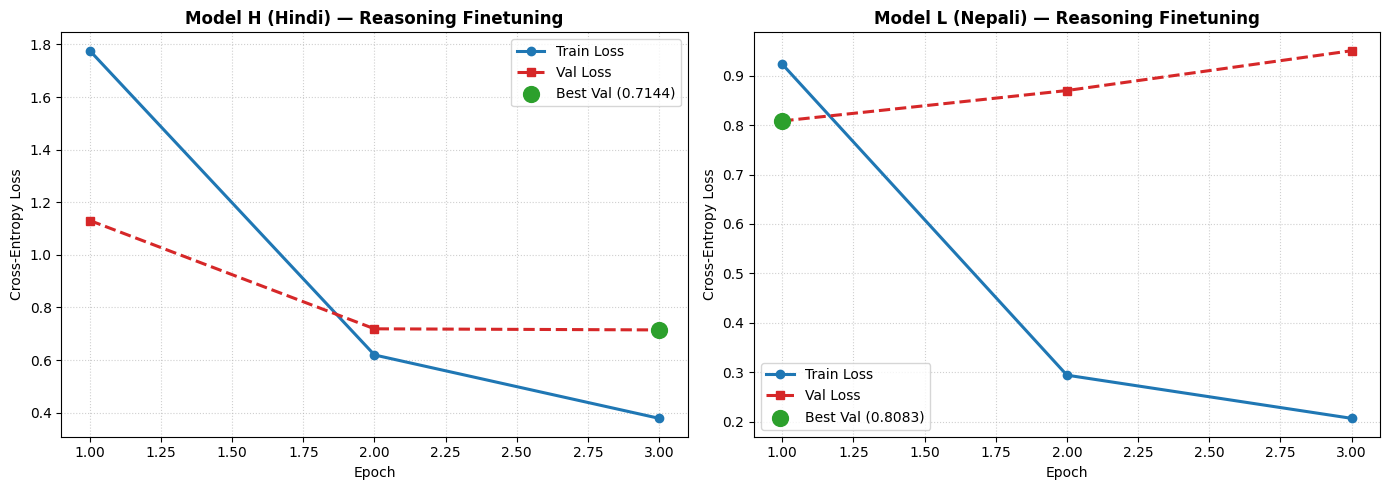

In [17]:
import pandas as pd

def plot_finetuning_curves(combined_csv="finetune_log_combined.csv"):
    df = pd.read_csv(combined_csv)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, (lang, title) in zip(axes, [("hindi", "Model H (Hindi)"), ("nepali", "Model L (Nepali)")]):
        sub = df[df["lang"] == lang]
        if sub.empty:
            ax.text(0.5, 0.5, f"No log data for {title}", ha='center', va='center', transform=ax.transAxes)
            ax.set_title(title)
            continue
        ax.plot(sub["epoch"], sub["train_loss"], marker='o', linewidth=2.2, color='#1f77b4', label='Train Loss')
        ax.plot(sub["epoch"], sub["val_loss"], marker='s', linewidth=2.2, color='#d62728', linestyle='--', label='Val Loss')
        min_idx = sub["val_loss"].idxmin()
        ax.scatter([sub.loc[min_idx, "epoch"]], [sub.loc[min_idx, "val_loss"]], color='#2ca02c', s=130, zorder=5,
                    label=f'Best Val ({sub.loc[min_idx, "val_loss"]:.4f})')
        ax.set_title(f"{title} — Reasoning Finetuning", fontsize=12, fontweight='bold')
        ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-Entropy Loss")
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(frameon=True, fontsize=10)
    plt.tight_layout()
    os.makedirs("report", exist_ok=True)
    plt.savefig("report/finetuning_loss_curves.png", dpi=300, bbox_inches="tight")
    print("Plot saved to report/finetuning_loss_curves.png")
    plt.show()

plot_finetuning_curves()

### Export finetuned checkpoints to Hugging Face Hub

Uploads everything in `checkpoints/finetuned/{hindi,nepali}/` (per-epoch checkpoints,
the best checkpoint, `finetune_config.json`) to a HF model repo, mirroring how the
pretrained checkpoints were already hosted there. Token is requested interactively —
nothing hardcoded, nothing left sitting in the notebook.

In [18]:
from huggingface_hub import HfApi, login

from kaggle_secrets import UserSecretsClient

secrets = UserSecretsClient()
HF_TOKEN = secrets.get_secret("HF_TOKEN")

login(token=HF_TOKEN, add_to_git_credential=False)

FINETUNED_REPO_ID = "manyajain111/lma-phase3-finetuned"  # change if you want a different repo name

api = HfApi()
api.create_repo(repo_id=FINETUNED_REPO_ID, repo_type="model", exist_ok=True, private=False)

for lang_full in ["hindi", "nepali"]:
    local_dir = f"checkpoints/finetuned/{lang_full}"
    if not os.path.isdir(local_dir):
        print(f"Skipping {lang_full}: {local_dir} not found (run finetuning first).")
        continue
    print(f"Uploading {local_dir} -> {FINETUNED_REPO_ID}/{lang_full} ...")
    api.upload_folder(
        folder_path=local_dir,
        path_in_repo=lang_full,
        repo_id=FINETUNED_REPO_ID,
        repo_type="model",
        commit_message=f"Upload finetuned {lang_full} checkpoints (Phase 3)",
    )

print(f"\nDone. https://huggingface.co/{FINETUNED_REPO_ID}")

del HF_TOKEN  # don't leave the token sitting in a variable longer than needed

HfHubHTTPError: (Request ID: Root=1-6aaa66a7-04138c366adb9eee52fc02be;5341b2c9-c176-4d3c-9fc7-ce28c97575c4)

403 Forbidden: You don't have the rights to create a model under the namespace "manyajain111".
Cannot access content at: https://huggingface.co/api/repos/create.
Make sure your token has the correct permissions.